In [1]:
from typing import Literal
from langgraph.graph import StateGraph, MessagesState
from langgraph.constants import START, END
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage
from IPython.display import Image, display
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
# 定义模型
llm = init_chat_model(
    model="deepseek-flash",
    extra_body={"thinking": {"type": "disabled"}}
)

In [3]:
# 定义state
class IntentState(MessagesState):
    intent: str # 意图识别
    # messages messagesState自带了messages字段

In [4]:
# 定义node
def intent_node(state: IntentState):
    message = f'''
    根据用户的输入判断用户意图，可选意图：weather、translate、chat。
    user_query: {state['messages'][-1].content}
    '''
    # 调用模型，结果是AIMessage
    response = llm.invoke(message)
    # 更新state
    return {"intent": response.text}

def chat_node(state: IntentState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

def translate_node(state: IntentState):
    message = f'''
    将用户的输入翻译成英文，直接翻译不要解释。
    user_query: {state['messages'][-1].content}
    '''
    response = llm.invoke(message)
    return {"messages": [response]}

def weather_node(state: IntentState):
    return {"messages": [AIMessage(content="今天天气晴朗，温度20度")]}

# 定义路由条件
def intent_route(state: IntentState) -> Literal["weather", "translate", "chat"]:
    return state["intent"]

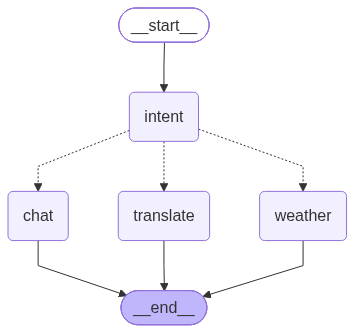

In [5]:
# 创建graph
builder = StateGraph(IntentState)

builder.add_node("intent", intent_node)
builder.add_node("chat", chat_node)
builder.add_node("translate", translate_node)
builder.add_node("weather", weather_node)

builder.add_edge(START, "intent")
builder.add_conditional_edges("intent", intent_route)
builder.add_edge("chat", END)
builder.add_edge("translate", END)
builder.add_edge("weather", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
# 测试
result = graph.invoke({"messages": [HumanMessage(content="你好 👋")]})
print(f"意图: {result['intent']}")
print(f"最终回答: {result['messages'][-1].content}")

意图: chat
最终回答: 你好！👋 很高兴见到你！有什么我可以帮你的吗？无论是回答问题、聊聊想法，还是需要一些建议，我都在这里～😊


In [8]:
# 测试
result = graph.invoke({"messages": [HumanMessage(content="今天天气怎么样")]})
print(f"意图: {result['intent']}")
print(f"最终回答: {result['messages'][-1].content}")

意图: weather
最终回答: 今天天气晴朗，温度20度


In [10]:
# 测试
result = graph.invoke({"messages": [HumanMessage(content="天气 的英文是什么")]})
print(f"意图: {result['intent']}")
print(f"最终回答: {result['messages'][-1].content}")

意图: translate
最终回答: What is the English for "weather"?
